In [1]:
!mkdir -p /content/data
!mv /content/model.py /content/labels.csv /content/train_idx.txt /content/val_idx.txt /content/train_images.npy /content/test_images.npy /content/classes.txt /content/results_template.json /content/data/

In [2]:

NAME = "Harshita Sinha"
ROLL_NO = "25b3941"
SEED = 0

EPOCHS = 50
EPOCHS_T3 = 15

DATA = "/content/data"
WORK = "/content/work"
# --------------------------------------------

import os, sys, json, shutil, subprocess
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

SUB = f"{WORK}/submission"
PRED = f"{SUB}/predictions"
os.makedirs(PRED, exist_ok=True)
os.makedirs(f"{SUB}/code", exist_ok=True)

sys.path.append(DATA)
from model import ResNet18

# Select the available device safely
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


Device: cuda
GPU: Tesla T4


In [3]:
labels = pd.read_csv(f"{DATA}/labels.csv").sort_values("index")
train_idx = np.loadtxt(f"{DATA}/train_idx.txt", dtype=int)
val_idx = np.loadtxt(f"{DATA}/val_idx.txt", dtype=int)
classes = open(f"{DATA}/classes.txt").read().split()

imgs = np.load(f"{DATA}/train_images.npy")
test_imgs = np.load(f"{DATA}/test_images.npy")

def to_tensor(a):
    # (N,32,32,3) uint8 -> (N,3,32,32) float in [0,1]
    return torch.tensor(a).permute(0, 3, 1, 2).float().div(255).to(device)

x_train = to_tensor(imgs[train_idx])
x_val = to_tensor(imgs[val_idx])
x_test = to_tensor(test_imgs)

# normalize with mean/std of the provided training images
mean = x_train.mean(dim=(0, 2, 3), keepdim=True)
std = x_train.std(dim=(0, 2, 3), keepdim=True)
x_train = (x_train - mean) / std
x_val = (x_val - mean) / std
x_test = (x_test - mean) / std

# labels of the train images (Y) and of the val images (Yv)
Y, Yv = {}, {}
for k in ["clean", "noisy", "synthetic"]:
    col = labels[k + "_label"].values
    Y[k] = torch.tensor(col[train_idx]).to(device)
    Yv[k] = torch.tensor(col[val_idx]).to(device)

# mask of the mislabeled train images. Only used to MEASURE things (Task 1 / 2 and my own Task 3 check)
wrong = Y["noisy"] != Y["clean"]
all_ids = torch.arange(len(x_train), device=device)
print(x_train.shape, x_val.shape, x_test.shape)

# results.json is filled in as we go
results = json.load(open(f"{DATA}/results_template.json"))
results["name"] = NAME
results["roll_no"] = ROLL_NO
results["seed"] = SEED
results["training_setup"] = {
    "optimizer": "SGD, momentum 0.9, nesterov, weight decay 5e-4, lr 0.05",
    "learning_rate_schedule": "cosine annealing, stepped once per epoch",
    "batch_size": 128,
    "epochs": EPOCHS,
    "augmentation": "random crop (padding 4) + random horizontal flip",
    "gpu_used": torch.cuda.get_device_name(0),
}

torch.Size([45000, 3, 32, 32]) torch.Size([5000, 3, 32, 32]) torch.Size([10000, 3, 32, 32])


In [4]:
def augment(x):

    x = F.pad(x, (4, 4, 4, 4))
    parts = []
    for chunk in x.chunk(8):
        i, j = np.random.randint(0, 9, 2)
        parts.append(chunk[:, :, i:i + 32, j:j + 32])
    x = torch.cat(parts)
    flip = torch.rand(len(x), device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)

def predict(model, x):

    model.eval()
    out = []
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        for k in range(0, len(x), 1000):
            out.append(model(x[k:k + 1000]).float())
    return torch.cat(out)

def save_preds(fname, preds):
    pd.DataFrame({"id": np.arange(len(preds)), "pred": preds}).to_csv(f"{PRED}/{fname}", index=False)

noise rate: 0.4024
            airplane  automobile  bird   cat  deer   dog  frog  horse  ship  \
airplane        2925         293   314    89    94   105    85     75   379   
automobile       191        2657    63   116    80    68    60     64    71   
bird             263         165  2842   212   254   216   222    147   106   
cat              180         160   354  2168   194   924   206    106    91   
deer             184         142   316   184  2195   491   174    683    94   
dog              150         131   240   834   183  2620   123    136    55   
frog             170         166   373   350   229   257  2676    124    96   
horse            179         120   111   100   233   289   101   3246    77   
ship             369         333    94    65    96    79    71     99  3076   
truck            180        1247    81    87    78    81    52     68   115   

            truck  
airplane      146  
automobile   1126  
bird           77  
cat            86  
deer       

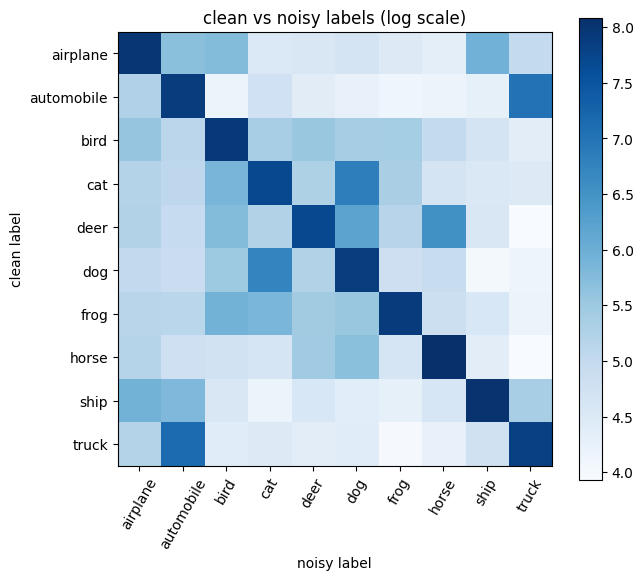

automobile <-> truck 2373 (13.1% of all wrong labels)
cat <-> dog 1758 (9.7% of all wrong labels)
deer <-> horse 916 (5.1% of all wrong labels)
airplane <-> ship 748 (4.1% of all wrong labels)
deer <-> dog 674 (3.7% of all wrong labels)


In [5]:
#TASK-1

c = Y["clean"].cpu().numpy()
n = Y["noisy"].cpu().numpy()
noise_rate = (c != n).mean()
print("noise rate:", round(noise_rate, 4))

cm = np.zeros((10, 10), dtype=int)
for a, b in zip(c, n):
    cm[a, b] += 1
print(pd.DataFrame(cm, index=classes, columns=classes))

plt.figure(figsize=(7, 6))
plt.imshow(np.log1p(cm), cmap="Blues")
plt.xticks(range(10), classes, rotation=60)
plt.yticks(range(10), classes)
plt.xlabel("noisy label")
plt.ylabel("clean label")
plt.title("clean vs noisy labels (log scale)")
plt.colorbar()
plt.show()

pairs = []
for i in range(10):
    for j in range(i + 1, 10):
        pairs.append((cm[i, j] + cm[j, i], classes[i], classes[j]))
pairs.sort(reverse=True)
total_wrong = (c != n).sum()
top_pairs = [(a, b, cnt, 100 * cnt / total_wrong) for cnt, a, b in pairs[:5]]
for a, b, cnt, pct in top_pairs:
    print(a, "<->", b, cnt, f"({pct:.1f}% of all wrong labels)")

results["task1"]["noise_rate"] = round(float(noise_rate), 4)

In [6]:
logs, test_preds, models = {}, {}, {}
for name in ["clean", "noisy"]:
    use_labels = Y[name]
    use_ids = all_ids
    loss_fn = nn.CrossEntropyLoss()
    n_epochs = EPOCHS
    log, preds = [], []
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    model = ResNet18(10).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=5e-4, nesterov=True)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs)
    scaler = torch.cuda.amp.GradScaler()
    for ep in range(1, n_epochs + 1):
        model.train()
        perm = use_ids[torch.randperm(len(use_ids), device=device)]
        for k in range(0, len(perm), 128):
            b = perm[k:k + 128]
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(augment(x_train[b]))
            loss = loss_fn(out.float(), use_labels[b])
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
        sched.step()

        pv = predict(model, x_val).argmax(1)
        row = {"epoch": ep, "val_acc_noisy": (pv == Yv["noisy"]).float().mean().item()}
        if name == "noisy":

            pt = predict(model, x_train).argmax(1)
            hit = pt == use_labels
            row["train_acc_correct"] = hit[~wrong].float().mean().item()
            row["train_acc_mislabeled"] = hit[wrong].float().mean().item()
            row["val_acc_clean"] = (pv == Yv["clean"]).float().mean().item()
        log.append(row)
        preds.append(predict(model, x_test).argmax(1).cpu().numpy())
        print(name, "epoch", ep, "val acc (noisy labels):", round(row["val_acc_noisy"], 4))
    logs[name] = pd.DataFrame(log)
    test_preds[name] = np.array(preds)
    models[name] = model


save_preds("t1_clean_ref.csv", test_preds["clean"][-1])
save_preds("t1_noisy_ce.csv", test_preds["noisy"][-1])

results["task1"]["val_acc_noisy_labels__clean_ref_model"] = round(logs["clean"].val_acc_noisy.iloc[-1], 4)
results["task1"]["val_acc_noisy_labels__noisy_ce_model"] = round(logs["noisy"].val_acc_noisy.iloc[-1], 4)
print("clean ref  val acc (noisy labels):", logs["clean"].val_acc_noisy.iloc[-1])
print("noisy CE   val acc (noisy labels):", logs["noisy"].val_acc_noisy.iloc[-1])

/tmp/ipykernel_755/2870793242.py:13: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


clean epoch 1 val acc (noisy labels): 0.3908
clean epoch 2 val acc (noisy labels): 0.4378
clean epoch 3 val acc (noisy labels): 0.4742
clean epoch 4 val acc (noisy labels): 0.4854
clean epoch 5 val acc (noisy labels): 0.5112
clean epoch 6 val acc (noisy labels): 0.525
clean epoch 7 val acc (noisy labels): 0.519
clean epoch 8 val acc (noisy labels): 0.5238
clean epoch 9 val acc (noisy labels): 0.5544
clean epoch 10 val acc (noisy labels): 0.547
clean epoch 11 val acc (noisy labels): 0.5418
clean epoch 12 val acc (noisy labels): 0.5612
clean epoch 13 val acc (noisy labels): 0.569
clean epoch 14 val acc (noisy labels): 0.5548
clean epoch 15 val acc (noisy labels): 0.5504
clean epoch 16 val acc (noisy labels): 0.541
clean epoch 17 val acc (noisy labels): 0.5658
clean epoch 18 val acc (noisy labels): 0.5658
clean epoch 19 val acc (noisy labels): 0.5708
clean epoch 20 val acc (noisy labels): 0.5678
clean epoch 21 val acc (noisy labels): 0.5634
clean epoch 22 val acc (noisy labels): 0.5672
cl

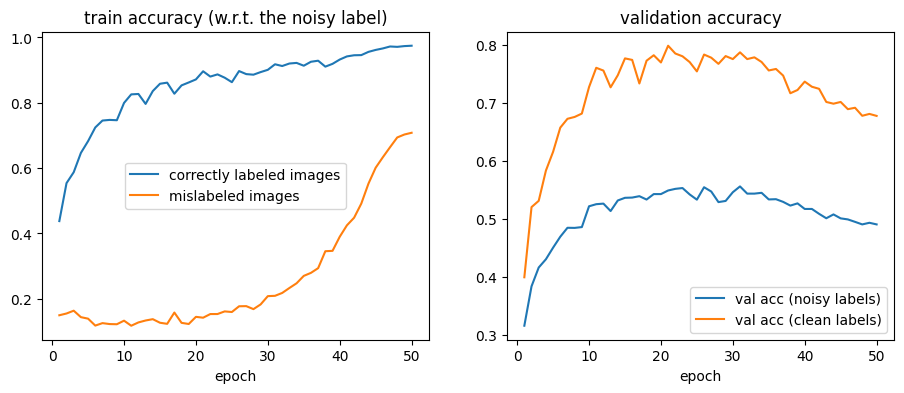

early stopping epoch: 31
memorization starts around epoch: 21
    epoch  train_acc_correct  train_acc_mislabeled  val_acc_noisy  \
0       1              0.438                 0.149          0.316   
1       2              0.554                 0.155          0.384   
2       3              0.587                 0.163          0.417   
3       4              0.646                 0.144          0.431   
4       5              0.682                 0.139          0.451   
5       6              0.724                 0.118          0.470   
6       7              0.745                 0.125          0.485   
7       8              0.747                 0.122          0.485   
8       9              0.746                 0.122          0.486   
9      10              0.799                 0.133          0.522   
10     11              0.826                 0.117          0.526   
11     12              0.827                 0.127          0.527   
12     13              0.796             

In [7]:
#TASK-2
L = logs["noisy"]
L[["epoch", "train_acc_correct", "train_acc_mislabeled", "val_acc_noisy", "val_acc_clean"]] \
    .to_csv(f"{PRED}/t2_dynamics.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(L.epoch, L.train_acc_correct, label="correctly labeled images")
ax[0].plot(L.epoch, L.train_acc_mislabeled, label="mislabeled images")
ax[0].set_title("train accuracy (w.r.t. the noisy label)")
ax[0].set_xlabel("epoch")
ax[0].legend()
ax[1].plot(L.epoch, L.val_acc_noisy, label="val acc (noisy labels)")
ax[1].plot(L.epoch, L.val_acc_clean, label="val acc (clean labels)")
ax[1].set_title("validation accuracy")
ax[1].set_xlabel("epoch")
ax[1].legend()
plt.show()

es_idx = L.val_acc_noisy.idxmax()
es_epoch = int(L.epoch[es_idx])
save_preds("t2_early_stop.csv", test_preds["noisy"][es_idx])
results["task2"]["early_stop_epoch"] = es_epoch
results["task2"]["val_acc_noisy_labels_at_early_stop"] = round(L.val_acc_noisy[es_idx], 4)
print("early stopping epoch:", es_epoch)

mem_epoch = int(L.epoch[L.val_acc_clean.idxmax()])
results["task2"]["memorization_start_epoch"] = mem_epoch
print("memorization starts around epoch:", mem_epoch)
print(L[["epoch", "train_acc_correct", "train_acc_mislabeled", "val_acc_noisy", "val_acc_clean"]].round(3))

In [8]:
#TASK-3
K = 3
perm_all = np.random.RandomState(SEED).permutation(len(x_train))
folds = np.array_split(perm_all, K)
oof_noisy = torch.zeros(len(x_train), 10, device=device)

for f in range(K):
    held = torch.tensor(folds[f], device=device)
    rest = torch.tensor(np.concatenate([folds[g] for g in range(K) if g != f]), device=device)
    use_labels = Y["noisy"]
    use_ids = rest
    loss_fn = nn.CrossEntropyLoss()
    n_epochs = EPOCHS_T3
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    model = ResNet18(10).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=5e-4, nesterov=True)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs)
    scaler = torch.cuda.amp.GradScaler()
    for ep in range(1, n_epochs + 1):
        model.train()
        perm = use_ids[torch.randperm(len(use_ids), device=device)]
        for k in range(0, len(perm), 128):
            b = perm[k:k + 128]
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(augment(x_train[b]))
            loss = loss_fn(out.float(), use_labels[b])
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
        sched.step()
        print("fold", f, "epoch", ep)
    oof_noisy[held] = F.softmax(predict(model, x_train[held]), dim=1)

/tmp/ipykernel_755/3551654010.py:19: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


fold 0 epoch 1
fold 0 epoch 2
fold 0 epoch 3
fold 0 epoch 4
fold 0 epoch 5
fold 0 epoch 6
fold 0 epoch 7
fold 0 epoch 8
fold 0 epoch 9
fold 0 epoch 10
fold 0 epoch 11
fold 0 epoch 12
fold 0 epoch 13
fold 0 epoch 14
fold 0 epoch 15
fold 1 epoch 1
fold 1 epoch 2
fold 1 epoch 3
fold 1 epoch 4
fold 1 epoch 5
fold 1 epoch 6
fold 1 epoch 7
fold 1 epoch 8
fold 1 epoch 9
fold 1 epoch 10
fold 1 epoch 11
fold 1 epoch 12
fold 1 epoch 13
fold 1 epoch 14
fold 1 epoch 15
fold 2 epoch 1
fold 2 epoch 2
fold 2 epoch 3
fold 2 epoch 4
fold 2 epoch 5
fold 2 epoch 6
fold 2 epoch 7
fold 2 epoch 8
fold 2 epoch 9
fold 2 epoch 10
fold 2 epoch 11
fold 2 epoch 12
fold 2 epoch 13
fold 2 epoch 14
fold 2 epoch 15


In [9]:
y = Y["noisy"]
ar = torch.arange(len(y), device=device)
p_given = oof_noisy[ar, y]

scores = {}
scores["cv_loss"] = -torch.log(p_given + 1e-8)
scores["plain_loss"] = F.cross_entropy(predict(models["noisy"], x_train), y, reduction="none")


w = wrong.cpu().numpy()
k = int(w.sum())
rows = []
for name, s in scores.items():
    s = s.cpu().numpy()
    top = np.argsort(-s)[:k]
    rows.append({"signal": name, "AUROC": roc_auc_score(w, s), "precision@k": w[top].mean()})
t3 = pd.DataFrame(rows).sort_values("AUROC", ascending=False).reset_index(drop=True)
print(t3.round(4))

best_signal = t3.signal[0]
pd.DataFrame({"index": train_idx, "score": scores[best_signal].cpu().numpy()}) \
    .to_csv(f"{PRED}/t3_noise_scores.csv", index=False)
results["task3"]["method"] = f"{best_signal} from 3-fold cross validation on the noisy labels"

       signal   AUROC  precision@k
0     cv_loss  0.9271       0.8100
1  plain_loss  0.7405       0.6201


In [10]:
#TASK-4
use_labels = Y["noisy"]
use_ids = all_ids
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.2)
n_epochs = EPOCHS
log, preds = [], []
torch.manual_seed(SEED)
np.random.seed(SEED)
model = ResNet18(10).to(device)
opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=5e-4, nesterov=True)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs)
scaler = torch.cuda.amp.GradScaler()
for ep in range(1, n_epochs + 1):
    model.train()
    perm = use_ids[torch.randperm(len(use_ids), device=device)]
    for k in range(0, len(perm), 128):
        b = perm[k:k + 128]
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(augment(x_train[b]))
        loss = loss_fn(out.float(), use_labels[b])
        opt.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
    sched.step()
    pv = predict(model, x_val).argmax(1)
    log.append({"epoch": ep, "val_acc_noisy": (pv == Yv["noisy"]).float().mean().item()})
    preds.append(predict(model, x_test).argmax(1).cpu().numpy())
    print("label smoothing epoch", ep, "val acc (noisy labels):", round(log[-1]["val_acc_noisy"], 4))

ls_log = pd.DataFrame(log)
ls_preds = np.array(preds)
b = ls_log.val_acc_noisy.idxmax()
best_method = "label_smoothing"
best_val = ls_log.val_acc_noisy[b]
save_preds("t4_label_smoothing.csv", ls_preds[b])

results["task4"]["methods"] = [{"name": best_method, "file": "t4_label_smoothing.csv", "val_acc_noisy_labels": round(best_val, 4)}]
results["task4"]["best_method"] = best_method
base_final = logs["noisy"].val_acc_noisy.iloc[-1]
print("best epoch", int(ls_log.epoch[b]), "| label smoothing val acc:", round(best_val, 4), "| CE baseline (final epoch):", round(base_final, 4))

/tmp/ipykernel_755/2645209916.py:12: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


label smoothing epoch 1 val acc (noisy labels): 0.3396
label smoothing epoch 2 val acc (noisy labels): 0.3744
label smoothing epoch 3 val acc (noisy labels): 0.4122
label smoothing epoch 4 val acc (noisy labels): 0.416
label smoothing epoch 5 val acc (noisy labels): 0.4358
label smoothing epoch 6 val acc (noisy labels): 0.4772
label smoothing epoch 7 val acc (noisy labels): 0.4856
label smoothing epoch 8 val acc (noisy labels): 0.4966
label smoothing epoch 9 val acc (noisy labels): 0.4982
label smoothing epoch 10 val acc (noisy labels): 0.5146
label smoothing epoch 11 val acc (noisy labels): 0.516
label smoothing epoch 12 val acc (noisy labels): 0.5198
label smoothing epoch 13 val acc (noisy labels): 0.5054
label smoothing epoch 14 val acc (noisy labels): 0.5358
label smoothing epoch 15 val acc (noisy labels): 0.537
label smoothing epoch 16 val acc (noisy labels): 0.5418
label smoothing epoch 17 val acc (noisy labels): 0.5308
label smoothing epoch 18 val acc (noisy labels): 0.52
label 

In [11]:
#TASK-5
configs = {"baseline": nn.CrossEntropyLoss(), "label_smoothing": nn.CrossEntropyLoss(label_smoothing=0.2)}

t5_logs, t5_preds = {}, {}
for name in configs:
    use_labels = Y["synthetic"]
    use_ids = all_ids
    loss_fn = configs[name]
    n_epochs = EPOCHS
    log, preds = [], []
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    model = ResNet18(10).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=5e-4, nesterov=True)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs)
    scaler = torch.cuda.amp.GradScaler()
    for ep in range(1, n_epochs + 1):
        model.train()
        perm = use_ids[torch.randperm(len(use_ids), device=device)]
        for k in range(0, len(perm), 128):
            b = perm[k:k + 128]
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(augment(x_train[b]))
            loss = loss_fn(out.float(), use_labels[b])
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
        sched.step()
        pv = predict(model, x_val).argmax(1)
        log.append({"epoch": ep, "val_acc_synth": (pv == Yv["synthetic"]).float().mean().item()})
        preds.append(predict(model, x_test).argmax(1).cpu().numpy())
        print("synthetic", name, "epoch", ep, "val acc (synthetic labels):", round(log[-1]["val_acc_synth"], 4))
    t5_logs[name] = pd.DataFrame(log)
    t5_preds[name] = np.array(preds)

save_preds("t5_baseline_synth.csv", t5_preds["baseline"][-1])
synth_base = t5_logs["baseline"].val_acc_synth.iloc[-1]
b5 = t5_logs["label_smoothing"].val_acc_synth.idxmax()
save_preds("t5_best_synth.csv", t5_preds["label_smoothing"][b5])
synth_best = t5_logs["label_smoothing"].val_acc_synth[b5]

results["task5"]["val_acc_synthetic_labels__baseline"] = round(synth_base, 4)
results["task5"]["val_acc_synthetic_labels__best_method"] = round(synth_best, 4)
print("real noise      : CE", round(base_final, 4), "| label smoothing", round(best_val, 4))
print("synthetic noise : CE", round(synth_base, 4), "| label smoothing", round(synth_best, 4))

json.dump(results, open(f"{SUB}/results.json", "w"), indent=2)

/tmp/ipykernel_755/3562186450.py:16: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


synthetic baseline epoch 1 val acc (synthetic labels): 0.2554
synthetic baseline epoch 2 val acc (synthetic labels): 0.2746
synthetic baseline epoch 3 val acc (synthetic labels): 0.313
synthetic baseline epoch 4 val acc (synthetic labels): 0.3298
synthetic baseline epoch 5 val acc (synthetic labels): 0.38
synthetic baseline epoch 6 val acc (synthetic labels): 0.3822
synthetic baseline epoch 7 val acc (synthetic labels): 0.3854
synthetic baseline epoch 8 val acc (synthetic labels): 0.4118
synthetic baseline epoch 9 val acc (synthetic labels): 0.4248
synthetic baseline epoch 10 val acc (synthetic labels): 0.4338
synthetic baseline epoch 11 val acc (synthetic labels): 0.4344
synthetic baseline epoch 12 val acc (synthetic labels): 0.4506
synthetic baseline epoch 13 val acc (synthetic labels): 0.45
synthetic baseline epoch 14 val acc (synthetic labels): 0.4636
synthetic baseline epoch 15 val acc (synthetic labels): 0.466
synthetic baseline epoch 16 val acc (synthetic labels): 0.4748
synthet

In [ ]:
NAME = "Harshita Sinha"
ROLL_NO = "25b3941"

readme = f'''# CV Selection Bootcamp - CIFAR-10N ({NAME}, {ROLL_NO})

All five tasks are in one notebook, `CV_Bootcamp.ipynb`. To reproduce: open it in Google Colab with a GPU runtime,
upload the provided files, set the paths at the top and use Runtime > Run all.
Seed = {SEED}, epochs per network = {EPOCHS} (cross-validation runs: {EPOCHS_T3}).

Setup used for every run: ResNet-18 from model.py trained from scratch, SGD (momentum 0.9, nesterov, weight decay 5e-4),
lr 0.05 with cosine schedule, batch size 128, random crop + flip.

- Task 1: section "Task 1" -> t1_clean_ref.csv, t1_noisy_ce.csv (final epoch of each).
- Task 2: section "Task 2" -> t2_dynamics.csv, t2_early_stop.csv (epoch with the best noisy validation accuracy).
- Task 3: section "Task 3" -> t3_noise_scores.csv (3-fold cross validation, best signal: {best_signal}).
- Task 4: section "Task 4" -> t4_label_smoothing.csv (label smoothing 0.2).
- Task 5: section "Task 5" -> t5_baseline_synth.csv, t5_best_synth.csv.

Clean labels are used only for the Task 1 reference model and for measuring (confusion matrix, Task 2 curves, my Task 3 check).
'''
open(f"{SUB}/code/README.md", "w").write(readme)
shutil.copy(f"{DATA}/model.py", f"{SUB}/code/model.py")


try:
    from google.colab import _message
    nb = _message.blocking_request("get_ipynb", request="", timeout_sec=120)["ipynb"]
    json.dump(nb, open(f"{SUB}/code/CV_Bootcamp.ipynb", "w"))
except Exception as e:
    print("could not save the notebook automatically:", e)

tmp = f"{WORK}/zip_tmp"
shutil.rmtree(tmp, ignore_errors=True)
for item in ["code", "predictions"]:
    shutil.copytree(f"{SUB}/{item}", f"{tmp}/{item}")

    shutil.copy(f"{SUB}/results.json", f"{tmp}/results.json")
zip_path = shutil.make_archive(f"{WORK}/{ROLL_NO}_cv_bootcamp", "zip", tmp)
print("zip created:", zip_path)


print(subprocess.run(["python", "/content/check_format.py", zip_path], capture_output=True, text=True).stdout)

from google.colab import files
files.download(zip_path)